In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
movies = pd.read_csv('/Users/kushbajpai/Documents/Code/Movie Recommender/datasets/movies.csv')
ratings = pd.read_csv('/Users/kushbajpai/Documents/Code/Movie Recommender/datasets/ratings.csv')
scores = pd.read_csv('/Users/kushbajpai/Documents/Code/Movie Recommender/datasets/genome-scores.csv')
genome_tags = pd.read_csv('/Users/kushbajpai/Documents/Code/Movie Recommender/datasets/genome-tags.csv')
links = pd.read_csv('/Users/kushbajpai/Documents/Code/Movie Recommender/datasets/links.csv')
tags = pd.read_csv('/Users/kushbajpai/Documents/Code/Movie Recommender/datasets/tags.csv')
movies

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy
...,...,...,...
86532,288967,State of Siege: Temple Attack (2021),Action|Drama
86533,288971,Ouija Japan (2021),Action|Horror
86534,288975,The Men Who Made the Movies: Howard Hawks (1973),Documentary
86535,288977,Skinford: Death Sentence (2023),Crime|Thriller


In [3]:
movies.isna().sum()

movieId    0
title      0
genres     0
dtype: int64

In [4]:
print(scores.isna().sum())
scores

movieId      0
tagId        0
relevance    0
dtype: int64


,movieId,tagId,relevance
0,1,1,0.03200
1,1,2,0.02225
2,1,3,0.07000
3,1,4,0.05900
4,1,5,0.12300
...,...,...,...
18472123,288167,1124,0.09875
18472124,288167,1125,0.02950
18472125,288167,1126,0.02275
18472126,288167,1127,0.11225


In [5]:
print(genome_tags.isna().sum())
genome_tags

tagId    0
tag      0
dtype: int64


,tagId,tag
0,1,007
1,2,007 (series)
2,3,18th century
3,4,1920s
4,5,1930s
...,...,...
1123,1124,writing
1124,1125,wuxia
1125,1126,wwii
1126,1127,zombie


In [6]:
print(links.isna().sum())
links

movieId      0
imdbId       0
tmdbId     126
dtype: int64


,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0
3,4,114885,31357.0
4,5,113041,11862.0
...,...,...,...
86532,288967,14418234,845861.0
86533,288971,11162178,878958.0
86534,288975,70199,150392.0
86535,288977,23050520,1102551.0


In [7]:
print(ratings.isna().sum(),"\n\nRatings:\n")
ratings

userId       0
movieId      0
rating       0
timestamp    0
dtype: int64 

Ratings:



,userId,movieId,rating,timestamp
0,1,1,4.0,1225734739
1,1,110,4.0,1225865086
2,1,158,4.0,1225733503
3,1,260,4.5,1225735204
4,1,356,5.0,1225735119
...,...,...,...,...
33832157,330975,8340,2.0,1091583256
33832158,330975,8493,2.5,1091585709
33832159,330975,8622,4.0,1091581777
33832160,330975,8665,3.0,1091581765


In [8]:
ratings['rating'].describe()

count    3.383216e+07
mean     3.542540e+00
std      1.063959e+00
min      5.000000e-01
25%      3.000000e+00
50%      4.000000e+00
75%      4.000000e+00
max      5.000000e+00
Name: rating, dtype: float64

In [9]:
print(tags.isna().sum())
tags

userId        0
movieId       0
tag          17
timestamp     0
dtype: int64


,userId,movieId,tag,timestamp
0,10,260,good vs evil,1430666558
1,10,260,Harrison Ford,1430666505
2,10,260,sci-fi,1430666538
3,14,1221,Al Pacino,1311600756
4,14,1221,mafia,1311600746
...,...,...,...,...
2328310,330923,176599,politically correct,1507547491
2328311,330933,3317,coming of age,1351279384
2328312,330933,3317,sexuality,1351279389
2328313,330947,5782,Not Luc Besson,1154110902


In [10]:
tags=tags.dropna()

In [11]:
print(movies['movieId'].nunique())
print(links['movieId'].nunique())
print(scores['movieId'].nunique())
print(ratings['movieId'].nunique())
print(tags['movieId'].nunique())

86537
86537
16376
83239
53452


In [12]:
ratings['rating'].value_counts(normalize=True)

rating
4.0    0.261170
3.0    0.189189
5.0    0.146544
3.5    0.131975
4.5    0.092310
2.0    0.063445
2.5    0.052043
1.0    0.029961
0.5    0.016739
1.5    0.016624
Name: proportion, dtype: float64

In [13]:
movies['movieId'].nunique()

86537

In [14]:
ratings[ratings['rating']==5].nunique()

userId        284125
movieId        35281
rating             1
timestamp    4377722
dtype: int64

In [15]:
movies['genres'].nunique()

1796

In [16]:
datasets=[movies,scores,genome_tags,tags,ratings,links]
for dataset in datasets:
    print(dataset.duplicated().sum())

0
0
0
0
0
0


In [17]:
print(ratings['rating'].describe())

count    3.383216e+07
mean     3.542540e+00
std      1.063959e+00
min      5.000000e-01
25%      3.000000e+00
50%      4.000000e+00
75%      4.000000e+00
max      5.000000e+00
Name: rating, dtype: float64


In [18]:
movie_stats = (
    ratings.groupby("movieId")["rating"]
    .agg(['count', 'mean'])
    .reset_index()
)
movie_stats=movie_stats.rename(columns={
    "count":"#Ratings","mean":'Avg Rating'
})
movie_stats.head()

,movieId,#Ratings,Avg Rating
0,1,76813,3.893508
1,2,30209,3.278179
2,3,15820,3.171271
3,4,3028,2.868395
4,5,15801,3.076957


In [19]:
df = movies.merge(movie_stats, on="movieId")
df

,movieId,title,genres,#Ratings,Avg Rating
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,76813,3.893508
1,2,Jumanji (1995),Adventure|Children|Fantasy,30209,3.278179
2,3,Grumpier Old Men (1995),Comedy|Romance,15820,3.171271
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance,3028,2.868395
4,5,Father of the Bride Part II (1995),Comedy,15801,3.076957
...,...,...,...,...,...
83234,288967,State of Siege: Temple Attack (2021),Action|Drama,1,3.500000
83235,288971,Ouija Japan (2021),Action|Horror,1,0.500000
83236,288975,The Men Who Made the Movies: Howard Hawks (1973),Documentary,1,4.000000
83237,288977,Skinford: Death Sentence (2023),Crime|Thriller,1,3.000000


In [20]:
df['#Ratings'].describe()

count     83239.000000
mean        406.446041
std        2806.975876
min           1.000000
25%           2.000000
50%           5.000000
75%          26.000000
max      122296.000000
Name: #Ratings, dtype: float64

In [21]:
df[df['#Ratings']>=26].shape[0]

20958

In [22]:
df.describe()

,movieId,#Ratings,Avg Rating
count,83239.000000,83239.000000,83239.000000
mean,155280.437415,406.446041,3.012706
std,78926.635815,2806.975876,0.790872
min,1.000000,1.000000,0.500000
25%,107770.000000,2.000000,2.571429
50%,165131.000000,5.000000,3.083333
75%,211276.000000,26.000000,3.500000
max,288983.000000,122296.000000,5.000000


In [23]:
def weighted_rating(v, r, m, c):
    wr = ((v / (v + m)) * r) + ((m / (v + m)) * c)
    return wr


# Global average rating
c = df["Avg Rating"].mean()

# Minimum number of ratings = 75th percentile
threshold = df["#Ratings"].quantile(0.75)


# Calculate weighted rating for every movie
df["Weighted Avg Rating"] = df.apply(
    lambda row: weighted_rating(
        v=row["#Ratings"],
        r=row["Avg Rating"],
        m=threshold,
        c=c
    ),
    axis=1
)


# Create separate dataset for popularity-based recommendations
popularity_df = df[df["#Ratings"] >= threshold].copy()


# Sort by weighted rating
popularity_df = popularity_df.sort_values(
    "Weighted Avg Rating",
    ascending=False
)

print(popularity_df.shape)
popularity_df.head(10)

(20958, 6)


,movieId,title,genres,#Ratings,Avg Rating,Weighted Avg Rating
39322,159817,Planet Earth (2006),Documentary,3015,4.448093,4.435821
44214,171011,Planet Earth II (2016),Documentary,2041,4.451739,4.433638
314,318,"Shawshank Redemption, The (1994)",Crime|Drama,122296,4.416792,4.416494
44066,170705,Band of Brothers (2001),Action|Drama|War,2835,4.423986,4.411161
58750,202439,Parasite (2019),Comedy|Drama,12399,4.329946,4.327190
840,858,"Godfather, The (1972)",Crime|Drama,75004,4.326603,4.326147
44440,171495,Cosmos,(no genres listed),625,4.343200,4.290062
47999,179135,Blue Planet II (2017),Documentary,1267,4.312944,4.286798
56804,198185,Twin Peaks (1989),Drama|Mystery,1132,4.302562,4.273601
1190,1221,"Godfather: Part II, The (1974)",Crime|Drama,47271,4.269510,4.268819


In [24]:
df=df.sort_values(by='Weighted Avg Rating',ascending=False).reset_index(drop=True)
df

,movieId,title,genres,#Ratings,Avg Rating,Weighted Avg Rating
0,159817,Planet Earth (2006),Documentary,3015,4.448093,4.435821
1,171011,Planet Earth II (2016),Documentary,2041,4.451739,4.433638
2,318,"Shawshank Redemption, The (1994)",Crime|Drama,122296,4.416792,4.416494
3,170705,Band of Brothers (2001),Action|Drama|War,2835,4.423986,4.411161
4,202439,Parasite (2019),Comedy|Drama,12399,4.329946,4.327190
...,...,...,...,...,...,...
83234,31698,Son of the Mask (2005),Adventure|Children|Comedy|Fantasy,847,1.241440,1.294193
83235,6587,Gigli (2003),Comedy|Crime|Romance,872,1.214450,1.266515
83236,4775,Glitter (2001),Drama|Musical|Romance,788,1.151015,1.210480
83237,6483,From Justin to Kelly (2003),Musical|Romance,489,1.011247,1.112292


In [25]:
df['Weighted Avg Rating'].describe()

count    83239.000000
mean         3.058212
std          0.238521
min          1.069625
25%          2.958227
50%          3.028633
75%          3.109208
max          4.435821
Name: Weighted Avg Rating, dtype: float64

In [26]:
import plotly.express as px
px.histogram(x=df['Weighted Avg Rating'], title="Weighted Rating Average")

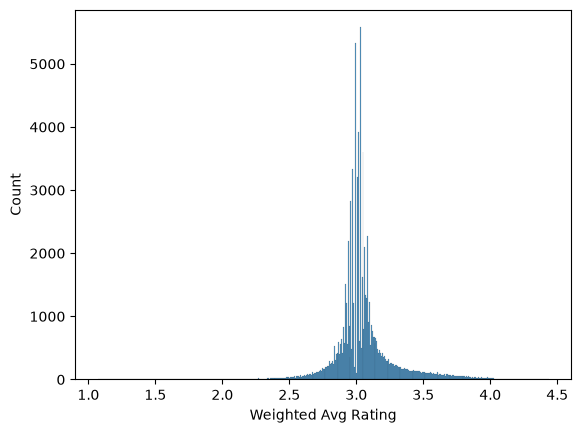

In [27]:
sns.histplot(x=df['Weighted Avg Rating'])
plt.show()

In [28]:
popular_movies = df.iloc[:25,:]
popular_movies

,movieId,title,genres,#Ratings,Avg Rating,Weighted Avg Rating
0,159817,Planet Earth (2006),Documentary,3015,4.448093,4.435821
1,171011,Planet Earth II (2016),Documentary,2041,4.451739,4.433638
2,318,"Shawshank Redemption, The (1994)",Crime|Drama,122296,4.416792,4.416494
3,170705,Band of Brothers (2001),Action|Drama|War,2835,4.423986,4.411161
4,202439,Parasite (2019),Comedy|Drama,12399,4.329946,4.327190
5,858,"Godfather, The (1972)",Crime|Drama,75004,4.326603,4.326147
6,171495,Cosmos,(no genres listed),625,4.343200,4.290062
7,179135,Blue Planet II (2017),Documentary,1267,4.312944,4.286798
8,198185,Twin Peaks (1989),Drama|Mystery,1132,4.302562,4.273601
9,1221,"Godfather: Part II, The (1974)",Crime|Drama,47271,4.269510,4.268819


In [29]:
df[df['movieId']==2959]['genres']

14    Action|Crime|Drama|Thriller
Name: genres, dtype: str

Content based Recommendation

In [30]:
genres = df['genres']
genres = list(genres)

vocab = list()

for genre in genres:
    vocab.append(genre.lower().strip().split('|'))
    
vocab.remove(['(no genres listed)'])

In [31]:
to_remove = ['(no genres listed)']
Genres = [genre for genre in vocab if genre != to_remove]
Genres

[['documentary'],
 ['documentary'],
 ['crime', 'drama'],
 ['action', 'drama', 'war'],
 ['comedy', 'drama'],
 ['crime', 'drama'],
 ['documentary'],
 ['drama', 'mystery'],
 ['crime', 'drama'],
 ['crime', 'mystery', 'thriller'],
 ['drama'],
 ['action', 'adventure', 'drama'],
 ['drama', 'war'],
 ['action', 'crime', 'drama', 'thriller'],
 ['adventure', 'animation', 'drama'],
 ['adventure', 'animation', 'fantasy'],
 ['mystery', 'thriller'],
 ['documentary'],
 ['drama'],
 ['drama'],
 ['comedy', 'war'],
 ['drama', 'romance', 'thriller'],
 ['drama', 'romance'],
 ['action', 'adventure', 'animation', 'sci-fi'],
 ['comedy', 'crime', 'drama', 'thriller'],
 ['crime', 'drama'],
 ['action', 'adventure', 'animation', 'sci-fi'],
 ['action', 'crime', 'drama', 'imax'],
 ['drama', 'film-noir', 'romance'],
 ['action', 'adventure', 'mystery', 'romance', 'thriller'],
 ['action', 'adventure', 'crime', 'drama', 'thriller'],
 ['crime', 'drama', 'film-noir'],
 ['film-noir', 'mystery', 'thriller'],
 ['action', 'cr

In [32]:
from gensim.models import Word2Vec
model = Word2Vec(
    sentences=Genres,
    vector_size=20,
    window=3,
    min_count=1,
    workers=4,
)
print(model.wv['drama'])
print(model.wv['crime'])

[-0.11914323  0.29714766  0.50553507  0.60012984 -0.3919763  -0.07251678
  0.57836926  0.6967364  -0.36573175 -0.05727413  0.6244238  -0.41494727
 -0.48204973  0.1992945  -0.20571795 -0.03158945  0.25570193 -0.01036859
 -0.5044707  -0.01613993]
[-0.11145566  0.05487385 -0.2799158  -0.05446895 -0.02250745  0.58919877
  0.38370332  0.15189363  0.18270282  0.23743185  0.854786   -0.48699468
 -0.46891034 -0.41540202  0.05410164  0.33571428  1.0627725   0.2985253
 -0.284283    0.51227695]


In [33]:
print(model.wv.most_similar('crime'))
print(model.wv.most_similar('drama'))

[('horror', 0.8263711333274841), ('war', 0.7514197826385498), ('film-noir', 0.7406936287879944), ('romance', 0.7397056221961975), ('mystery', 0.7228662371635437), ('western', 0.6937872767448425), ('documentary', 0.6685389280319214), ('sci-fi', 0.6545630097389221), ('thriller', 0.5758989453315735), ('action', 0.4987729489803314)]
[('musical', 0.7630330324172974), ('documentary', 0.7399241924285889), ('western', 0.683099627494812), ('action', 0.6567818522453308), ('film-noir', 0.6464584469795227), ('imax', 0.6258838772773743), ('mystery', 0.5845822095870972), ('comedy', 0.5539047122001648), ('fantasy', 0.5109165906906128), ('sci-fi', 0.5041797161102295)]


In [34]:
unique_genres = model.wv.index_to_key

In [35]:
genre_vectors = model.wv.vectors
genre_df = pd.DataFrame(data=genre_vectors)
genre_df.index = unique_genres
genre_df

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
drama,-0.119143,0.297148,0.505535,0.600130,-0.391976,-0.072517,0.578369,0.696736,-0.365732,-0.057274,0.624424,-0.414947,-0.482050,0.199294,-0.205718,-0.031589,0.255702,-0.010369,-0.504471,-0.016140
comedy,-0.120626,0.414841,0.474617,0.132155,0.263062,-0.071872,0.458987,0.523158,-0.506893,0.002767,-0.149138,-0.292797,0.275007,-0.256010,-0.187818,-0.102894,0.827212,-0.117452,-0.621848,-0.318246
thriller,-0.745608,0.960854,0.112866,0.089031,0.184400,0.127612,-0.018920,0.727583,0.022756,0.305646,0.168780,-0.065544,-0.614923,-0.517205,0.236181,-0.210999,1.020323,-0.292254,-0.701256,0.591700
romance,-0.030289,-0.145309,-0.330753,-0.323830,0.016540,0.283722,0.275757,0.364771,-0.347283,0.360852,0.527647,-0.119819,-0.153997,-0.271880,0.241538,0.140790,0.875590,0.413583,-0.599259,-0.246645
action,-0.384871,0.237096,0.549167,0.111768,0.152983,0.266541,0.607184,0.182410,-0.672004,0.454493,0.618807,-0.373706,-0.296908,-0.264982,0.107724,0.139301,-0.028901,0.154176,-0.334245,0.261643
documentary,-0.292614,0.214178,0.196803,0.015867,0.111791,0.095681,0.437019,0.385048,-0.330810,0.152971,0.331757,-0.397840,-0.111566,-0.057439,-0.010306,0.059031,0.551130,0.165622,-0.518335,0.022792
horror,-0.236125,0.143384,0.238611,-0.081241,0.148577,0.645000,0.472780,0.285239,-0.239176,0.560638,0.940594,-0.628462,-0.421266,-0.224775,0.192015,0.193861,0.395568,0.401370,-0.037737,0.584106
crime,-0.111456,0.054874,-0.279916,-0.054469,-0.022507,0.589199,0.383703,0.151894,0.182703,0.237432,0.854786,-0.486995,-0.468910,-0.415402,0.054102,0.335714,1.062773,0.298525,-0.284283,0.512277
adventure,-0.455779,0.345329,0.033945,-0.262363,0.225361,0.323739,0.677708,0.380342,-0.172828,0.365346,0.053554,-0.833946,0.461714,0.391120,-0.012569,-0.275082,0.507401,0.181531,-0.614093,-0.139470
sci-fi,-0.677045,0.233148,0.042009,-0.215856,0.139353,0.094336,0.530211,0.000276,-0.082045,0.046259,0.395763,-0.582285,-0.062008,-0.108631,-0.232671,0.042634,0.436804,0.065829,-0.686064,0.335771


In [36]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
genre_df_2D = pca.fit_transform(genre_df)
genre_df_2D.shape

(19, 2)

In [37]:
import plotly.express as px
px.scatter(x=genre_df_2D[:, 0], y=genre_df_2D[:, 1], color=unique_genres)

In [38]:
def cosine_similarity(a,b):
    
    dot_prod = np.dot(a, b)
    magnitude_a, magnitude_b = 0,0
    for i in range(len(a)):
        magnitude_a += a[i]**2
        magnitude_b += b[i]**2

    magnitude_a = np.sqrt(magnitude_a)
    magnitude_b = np.sqrt(magnitude_b)
        
    return (
        dot_prod / (magnitude_a*magnitude_b)
    )

drama = genre_df.loc['drama']
fantasy = genre_df.loc['fantasy']

cosine_similarity(drama, fantasy)

np.float32(0.51091665)

In [39]:
unique_genres
rows = dict()

for i in range(len(unique_genres)):
    genre_i = unique_genres[i]
    vector_i = model.wv[genre_i]
    
    row = dict()
    
    for j in range(len(unique_genres)):
        genre_j = unique_genres[j]
        vector_j = model.wv[genre_j]
        
        similarity = cosine_similarity(vector_i, vector_j)
        
        row[genre_j] = similarity
    rows[genre_i] = row

similarity_matrix = pd.DataFrame(rows).T
print(similarity_matrix.shape)
similarity_matrix

(19, 19)


,drama,comedy,thriller,romance,action,documentary,horror,crime,adventure,sci-fi,animation,children,mystery,fantasy,war,western,musical,film-noir,imax
drama,1.000000,0.553905,0.457113,0.342714,0.656782,0.739924,0.501386,0.394841,0.417650,0.504180,0.370919,0.408068,0.584582,0.510917,0.430627,0.683100,0.763033,0.646459,0.625884
comedy,0.553905,1.000000,0.550227,0.477731,0.454875,0.783015,0.232973,0.255836,0.659837,0.535856,0.631979,0.549614,0.454007,0.785195,0.770940,0.743254,0.822201,0.572643,0.700352
thriller,0.457113,0.550227,1.000000,0.454025,0.463066,0.668624,0.493196,0.575899,0.394369,0.603210,0.231743,0.090783,0.742199,0.353668,0.657167,0.715649,0.339202,0.808771,0.484485
romance,0.342714,0.477731,0.454025,1.000000,0.453617,0.738714,0.596982,0.739706,0.517469,0.527118,0.608252,0.594742,0.443494,0.597019,0.809173,0.741599,0.637981,0.565294,0.614674
action,0.656782,0.454875,0.463066,0.453617,1.000000,0.768852,0.817902,0.498773,0.482307,0.651790,0.496380,0.511388,0.769114,0.524027,0.533152,0.657778,0.558658,0.740695,0.747992
documentary,0.739924,0.783015,0.668624,0.738714,0.768852,1.000000,0.709922,0.668539,0.771857,0.828316,0.727592,0.707034,0.712336,0.836144,0.879884,0.963846,0.862792,0.774991,0.923932
horror,0.501386,0.232973,0.493196,0.596982,0.817902,0.709922,1.000000,0.826371,0.468906,0.635349,0.394257,0.377557,0.753306,0.393711,0.594159,0.644704,0.401424,0.756553,0.658472
crime,0.394841,0.255836,0.575899,0.739706,0.498773,0.668539,0.826371,1.000000,0.381625,0.654563,0.253739,0.304505,0.722866,0.342092,0.751420,0.693787,0.391753,0.740694,0.496531
adventure,0.417650,0.659837,0.394369,0.517469,0.482307,0.771857,0.468906,0.381625,1.000000,0.731020,0.893615,0.689844,0.352885,0.890320,0.684379,0.762407,0.723963,0.328815,0.900309
sci-fi,0.504180,0.535856,0.603210,0.527118,0.651790,0.828316,0.635349,0.654563,0.731020,1.000000,0.569043,0.676927,0.712644,0.720187,0.774999,0.866287,0.597095,0.601229,0.832539


In [40]:
similarity_matrix.describe()

,drama,comedy,thriller,romance,action,documentary,horror,crime,adventure,sci-fi,animation,children,mystery,fantasy,war,western,musical,film-noir,imax
count,19.000000,19.000000,19.000000,19.000000,19.000000,19.000000,19.000000,19.000000,19.000000,19.000000,19.000000,19.000000,19.000000,19.000000,19.000000,19.000000,19.000000,19.000000,19.000000
mean,0.557478,0.607076,0.530705,0.603174,0.620376,0.792964,0.592481,0.562818,0.634293,0.685387,0.588856,0.568833,0.583404,0.670591,0.715987,0.771638,0.671362,0.615870,0.743701
std,0.165651,0.191937,0.211885,0.153812,0.153392,0.096599,0.193115,0.214170,0.210981,0.130367,0.256926,0.241292,0.229653,0.237129,0.133777,0.108720,0.195591,0.220746,0.160602
min,0.342714,0.232973,0.090783,0.342714,0.453617,0.668539,0.232973,0.253739,0.328815,0.504180,0.177961,0.090783,0.177961,0.299865,0.430627,0.644704,0.339202,0.212190,0.484485
25%,0.424138,0.506794,0.424197,0.497600,0.497576,0.719964,0.435165,0.386689,0.443278,0.599162,0.382588,0.392812,0.414862,0.452314,0.627324,0.688443,0.520650,0.513103,0.620279
50%,0.510917,0.572643,0.493196,0.596982,0.558658,0.771857,0.596982,0.575899,0.684379,0.654563,0.613677,0.618243,0.636404,0.754811,0.724529,0.741599,0.724529,0.646459,0.755397
75%,0.651620,0.757097,0.662896,0.688348,0.744343,0.849468,0.731614,0.731286,0.767132,0.753009,0.758261,0.727135,0.732533,0.862564,0.772969,0.847800,0.819181,0.748624,0.883918
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [41]:
df.columns

Index(['movieId', 'title', 'genres', '#Ratings', 'Avg Rating',
       'Weighted Avg Rating'],
      dtype='str')

In [42]:
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd
import re

In [43]:
genre_lists = df["genres"].fillna("").str.split("|")

mlb = MultiLabelBinarizer()

genre_matrix = mlb.fit_transform(genre_lists)

genre_df = pd.DataFrame(
    genre_matrix,
    columns=mlb.classes_,
    index=df.index
)

movie_genres = pd.concat(
    [
        df[["movieId", "title"]],
        genre_df
    ],
    axis=1
)
movie_genres = movie_genres.drop(columns='(no genres listed)')
movie_genres.head()

,movieId,title,Action,Adventure,Animation,Children,Comedy,Crime,Documentary,Drama,...,Film-Noir,Horror,IMAX,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,159817,Planet Earth (2006),0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
1,171011,Planet Earth II (2016),0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
2,318,"Shawshank Redemption, The (1994)",0,0,0,0,0,1,0,1,...,0,0,0,0,0,0,0,0,0,0
3,170705,Band of Brothers (2001),1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,1,0
4,202439,Parasite (2019),0,0,0,0,1,0,0,1,...,0,0,0,0,0,0,0,0,0,0


In [44]:
movie_genres.shape

(83239, 21)

In [45]:
import re

def format_title(title):
    # Remove year
    title = re.sub(r"\s*\(\d{4}\)$", "", title)

    # Move ", The", ", A", ", An" to the beginning
    if title.endswith(", The"):
        title = "The " + title[:-5]

    elif title.endswith(", A"):
        title = "A " + title[:-3]

    elif title.endswith(", An"):
        title = "An " + title[:-4]

    return title.strip().lower()

In [46]:
movie_genres["formatted_title"] = movie_genres["title"].apply(format_title)

In [47]:
movie_genres["search_title"] = (
    movie_genres["formatted_title"]
    + " "
    + movie_genres["title"].str.extract(r"\((\d{4})\)$")[0]
)

In [48]:
movie_genres

,movieId,title,Action,Adventure,Animation,Children,Comedy,Crime,Documentary,Drama,...,IMAX,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western,formatted_title,search_title
0,159817,Planet Earth (2006),0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,planet earth,planet earth 2006
1,171011,Planet Earth II (2016),0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,planet earth ii,planet earth ii 2016
2,318,"Shawshank Redemption, The (1994)",0,0,0,0,0,1,0,1,...,0,0,0,0,0,0,0,0,the shawshank redemption,the shawshank redemption 1994
3,170705,Band of Brothers (2001),1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,1,0,band of brothers,band of brothers 2001
4,202439,Parasite (2019),0,0,0,0,1,0,0,1,...,0,0,0,0,0,0,0,0,parasite,parasite 2019
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83234,31698,Son of the Mask (2005),0,1,0,1,1,0,0,0,...,0,0,0,0,0,0,0,0,son of the mask,son of the mask 2005
83235,6587,Gigli (2003),0,0,0,0,1,1,0,0,...,0,0,0,1,0,0,0,0,gigli,gigli 2003
83236,4775,Glitter (2001),0,0,0,0,0,0,0,1,...,0,1,0,1,0,0,0,0,glitter,glitter 2001
83237,6483,From Justin to Kelly (2003),0,0,0,0,0,0,0,0,...,0,1,0,1,0,0,0,0,from justin to kelly,from justin to kelly 2003


In [49]:
genre_features = movie_genres.iloc[:, 3:-2]
genre_features.columns

Index(['Adventure', 'Animation', 'Children', 'Comedy', 'Crime', 'Documentary',
       'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'IMAX', 'Musical', 'Mystery',
       'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western'],
      dtype='str')

In [50]:
from sklearn.neighbors import NearestNeighbors

model = NearestNeighbors(
    metric="cosine",
    algorithm="brute"
)

model.fit(genre_features)

,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'brute'
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'cosine'
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"radius radius: float, default=1.0Range of parameter space to use by default for :meth:`radius_neighbors`queries.",1.0
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float (positive), default=2Parameter for the Minkowski metric fromsklearn.metrics.pairwise.pairwise_distances. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
Name,Type,Value
effective_metric_ effective_metric_: strMetric used to compute distances to neighbors.,str,'cosine'
effective_metric_params_ effective_metric_params_: dictParameters for the metric used to compute distances to neighbors.,dict,{}


In [51]:
movie = 'Back to the Future '
movie_index = movie_genres[movie_genres["formatted_title"] == movie.strip().lower()].index[0]
movie_index

462

In [52]:
distances, indices = model.kneighbors(
    genre_features.iloc[[movie_index]],
    n_neighbors=11
)
distances, indices

(array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]]),
 array([[70846,  9370, 20401,  5141,  5238,  5777, 80001, 79435, 78209,
          6300, 17975]]))

In [53]:
def recommend_movies(movie, n=10):

    movie_name = format_title(movie)
    
    matches = movie_genres[
        movie_genres['formatted_title'] == movie_name
    ]

    if matches.empty:
        print("Movie not found.")
        return

    if len(matches) > 1:
        print("Multiple movies found:")
        print(matches["search_title"].to_string(index=False))
        movie_name = input("Please choose one: ").lower().strip()
        matches = movie_genres[
                movie_genres['search_title'] == movie_name
            ]
        

    movie_index = matches.index[0]

    position = movie_genres.index.get_loc(movie_index)

    distances, indices = model.kneighbors(
        genre_features.iloc[[position]],
        n_neighbors=n + 1
    )

    recommendation_indices = [
    i for i in indices[0]
    if movie_genres.iloc[i]["formatted_title"] != movie_name
    ]

    recommendations = movie_genres.iloc[
        recommendation_indices
    ][["title","formatted_title"]].copy()

    print(f"Movies similar to {movie.strip().title()}:")
    return recommendations

In [54]:
recommend_movies("forrest Gump")

Movies similar to Forrest Gump:


,title,formatted_title
5654,Train of Life (Train de vie) (1998),train of life (train de vie)
21322,Tell It to the Marines (1926),tell it to the marines
3781,"Tiger and the Snow, The (La tigre e la neve) (...","tiger and the snow, the (la tigre e la neve)"
57139,Two Soldiers (1943),two soldiers
21081,Divine Intervention (Yadon ilaheyya) (2002),divine intervention (yadon ilaheyya)
7480,Their Finest (2017),their finest
41,Life Is Beautiful (La Vita è bella) (1997),life is beautiful (la vita è bella)
71839,Lazybones (1925),lazybones
6346,Music Within (2007),music within
4821,I Served the King of England (Obsluhoval jsem ...,i served the king of england (obsluhoval jsem ...


In [55]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(
    stop_words="english"
)
title_features = tfidf.fit_transform(
    movie_genres["formatted_title"]
)
title_features.shape

(83239, 41500)

In [56]:
title_model = NearestNeighbors(
    metric='cosine',
    algorithm='brute'
)
title_model.fit(title_features)

,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'brute'
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'cosine'
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"radius radius: float, default=1.0Range of parameter space to use by default for :meth:`radius_neighbors`queries.",1.0
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float (positive), default=2Parameter for the Minkowski metric fromsklearn.metrics.pairwise.pairwise_distances. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
Name,Type,Value
effective_metric_ effective_metric_: strMetric used to compute distances to neighbors.,str,'cosine'
effective_metric_params_ effective_metric_params_: dictParameters for the metric used to compute distances to neighbors.,dict,{}


In [57]:
movie=input('Movie: ')
movie = format_title(movie)
movie_index = movie_genres[movie_genres['formatted_title']==movie].index[0]

In [58]:
distances, indices = title_model.kneighbors(
    title_features[movie_index],
    n_neighbors=10
)

In [59]:
print('Movies similar to ',movie.title())
movie_genres.iloc[indices[0]][
    ["title",'formatted_title']
]

Movies similar to  The Godfather


,title,formatted_title
26359,GodFather (1991),godfather
5,"Godfather, The (1972)",the godfather
74882,GodFather (2022),godfather
26966,Our Godfather (2019),our godfather
79767,"Last Godfather, The (2010)",the last godfather
45284,Godfather's Story (2013),godfather's story
43029,The Black Godfather (2019),the black godfather
57578,The Black Godfather (1974),the black godfather
9,"Godfather: Part II, The (1974)",the godfather: part ii
5750,"Godfather: Part III, The (1990)",the godfather: part iii


In [60]:
recommend_movies(movie)

Movies similar to The Godfather:


,title,formatted_title
68548,Straightheads (Closure) (2007),straightheads (closure)
49481,Le septième juré (1962),le septième juré
25739,3 Days to Kill (2014),3 days to kill
70932,The Devil Strikes at Night (1957),the devil strikes at night
55556,Family of Cops II (1997),family of cops ii
3909,Metro Manila (2013),metro manila
7755,True Confessions (1981),true confessions
52601,Shed No Tears (1948),shed no tears
60340,Mystery Junction (1951),mystery junction
52623,Too Soon to Die (1966),too soon to die


In [61]:
genre_weight = 2
weighted_genres = genre_features*genre_weight

In [62]:
weighted_titles = title_features

In [63]:
from scipy.sparse import hstack

combined_features = hstack([
    weighted_titles,
    weighted_genres
])

In [64]:
combined_features = hstack([
    weighted_titles,
    weighted_genres
]).tocsr()

In [65]:
combined_features.shape

(83239, 41518)

In [66]:
combined_model = NearestNeighbors(
    metric="cosine",
    algorithm="brute"
)

combined_model.fit(combined_features)

,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'brute'
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'cosine'
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"radius radius: float, default=1.0Range of parameter space to use by default for :meth:`radius_neighbors`queries.",1.0
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float (positive), default=2Parameter for the Minkowski metric fromsklearn.metrics.pairwise.pairwise_distances. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
Name,Type,Value
effective_metric_ effective_metric_: strMetric used to compute distances to neighbors.,str,'cosine'
effective_metric_params_ effective_metric_params_: dictParameters for the metric used to compute distances to neighbors.,dict,{}


In [67]:
def recommend_movies(movie, n=10):

    movie_name = format_title(movie).lower()

    matches = movie_genres[
        movie_genres["formatted_title"] == movie_name
    ]

    if matches.empty:
        print("Movie not found.")
        return

    # Handle duplicate titles
    if len(matches) > 1:

        print("Multiple movies found:")

        for _, row in matches.iterrows():
            year = row["title"][-5:-1]
            print(f"{row['formatted_title'].title()} ({year})")

        year = input("Enter the year: ")

        selected = matches[
            matches["title"].str.endswith(f"({year})")
        ]

        if selected.empty:
            print("Invalid year.")
            return

        movie_index = selected.index[0]

    else:
        movie_index = matches.index[0]

    # Get the movie's position
    position = movie_genres.index.get_loc(movie_index)

    # Find similar movies
    distances, indices = combined_model.kneighbors(
        combined_features[position],
        n_neighbors=50
    )

    # Remove movies with the same title
    recommendation_indices = [
        i for i in indices[0]
        if movie_genres.iloc[i]["formatted_title"] != movie_name
    ][:n]

    # Create recommendations dataframe
    recommendations = movie_genres.iloc[
        recommendation_indices
    ][["title"]].copy()

    # Add similarity scores
    similarity_scores = []

    for i in recommendation_indices:
        position_in_results = list(indices[0]).index(i)
        similarity_scores.append(
            1 - distances[0][position_in_results]
        )

    recommendations["similarity"] = similarity_scores

    print(f"\nMovies similar to {movie_name.title()}:")

    return recommendations

In [73]:
movie = input('Movie: ')
movie = format_title(movie)
display(recommend_movies(movie))



Movies similar to Green Book:


,title,similarity
73581,Book of Love (2004),0.954928
76953,G (1983),0.942809
43244,All Together (2011),0.942809
63143,On Our Own (1998),0.942809
23271,Together (2021),0.942809
14956,Sometimes Always Never (2019),0.942809
71763,Everything About Her (2016),0.942809
8664,Please Give (2010),0.942809
9129,Where Do We Go Now? (2011),0.942809
5850,Nowhere (1997),0.942809
